# KQC MunchQubits — two circular transmons with a resonant coupler and a floating double-pad qubit (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/munch_qubits.py` (class `MunchQubits`, default parameters; © IQM
Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/munch_qubits.py`). Two grounded
`CircularTransmonSingleIsland` qubits (island radius 300 µm, two arc couplers each) are joined by a 9800 µm
resonant coupler (a = 3, b = 32 µm) with a meander between them; a floating `DoublePads` qubit sits below. Each
qubit has a readout resonator (11500, 12700, 8000 µm) from its coupler to a `SmoothCapacitor` on a T in one probe
line that crosses the chip from WN to EN, and a charge line (QB3's crosses the probe line on an airbridge).

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "EM1" |
| launchers | SMA8 (DL-QB1 = NW, DL-QB2 = NE, PL-1-OUT = EN, DL-QB3 = SE, PL-1-IN = WN), indent 800 µm | same assignment, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed 6 / 10 nH) | Quantcore trilayer SQUIDs: the two big circular islands (C_Σ ≈ 212 / 222 fF) **sized for 4.05 GHz** (fingers 0.26 / 0.27 µm, R_n 43.3 / 41.7 kΩ, L_J 6.48 / 6.24 nH); the double-pad qubit the nominal PDK SQUID (2 × 0.25 × 0.6 µm, 45 kΩ, 6.73 nH) |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`), no PDK band |
| elements, positions, routes | — | kept exactly; launcher legs derived from the launcher ports |
| placement | centred | centred (checked, no shift) |

**Kept exactly:** both circular qubits (all coupler, drive and SQUID parameters) at (3500, 7000) and
(6500, 7000); the DoublePads qubit with the chip's parameters (islands 1000 × 200 µm, gap 200 µm, ground gap
1400 × 900 µm, drive at (−1100, 400)) rotated 180° at (5000, 4000); the coupler path through (4500, 6500) →
(5500, 6500) with the total length 9800 µm and galvanic ends; the probe line with its three splitters (angles
180/90/0, lengths 50/150/50, with airbridges) at x = 3500, 5000, 6500 and y = 1500; the smooth capacitors (finger
control 3.32/4.21/1.46, 160 µm); the readout paths (bottom: capacitor corner → diagonal → up; top: coupler corner
→ 300 µm down; meander between) and total lengths; the charge-line paths including QB3's airbridge crossing.

**Simplified:** the probe line is four routes between the splitters instead of one waveguide with the splitters
inlined; the meanders are fitted by the router; `n_bridges` airbridges along the lines are left out. Both readout
ends are capacitive, so the readouts are λ/2 resonators, and the coupler (galvanic to both coupler arcs) is a λ/2
bus.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips corner rounding of the grid holes in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import size_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/munchqubits")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** KQC draws a SQUID in each qubit; `trilayer_junction` makes each a
Quantcore trilayer SQUID (KQC's `junction_width` = the straight finger, bent finger 0.6 µm). The two large
circular islands (C_Σ ≈ 212 / 222 fF without the junction, this design's LOM before the rebuild, hard-coded
here) would sit at ≈ 3.9–4.0 GHz with the nominal SQUID, below the PDK band, so `size_junction` sizes each for
4.05 GHz (R_n ≈ 43 / 42 kΩ, still in the window); the double-pad qubit gets the nominal SQUID.

In [4]:
LJ_PDK = trilayer_junction("DoublePads")[1]["Lj_nH"]
JJ_PARAMS, JUNCTION = {}, {}
for q, c in (("QB1", 212.3), ("QB2", 222.1)):
    s = size_junction(4.05, c, n=2, c_includes_junction=False)
    JJ_PARAMS[q], JUNCTION[q] = trilayer_junction("CircularTransmonSingleIsland", lj_nH=s.lj_nH, squid=True)
JJ_PARAMS["QB3"], JUNCTION["QB3"] = trilayer_junction("DoublePads", lj_nH=LJ_PDK, squid=True)
display(Markdown("| qubit | cell parameters | LOM junction |\n|---|---|---|\n" + "\n".join(
    f"| {q} | `{JJ_PARAMS[q]}` | `{JUNCTION[q]}` |" for q in JJ_PARAMS)))

| qubit | cell parameters | LOM junction |
|---|---|---|
| QB1 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.26}` | `{'Lj_nH': 6.4754, 'Cj_fF': 15.6}` |
| QB2 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.27}` | `{'Lj_nH': 6.2356, 'Cj_fF': 16.2}` |
| QB3 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.25}` | `{'Lj_nH': 6.7344, 'Cj_fF': 15.0}` |

## 3 · The die and its frame

10 × 10 mm with KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn) and the chip name
"EM1" (device ID). `with_grid=True`: KQC's whole-area ground grid, the original's cheese (the PDK band is then
not added). The Quantcore frame replaces KQC's ChipFrame.

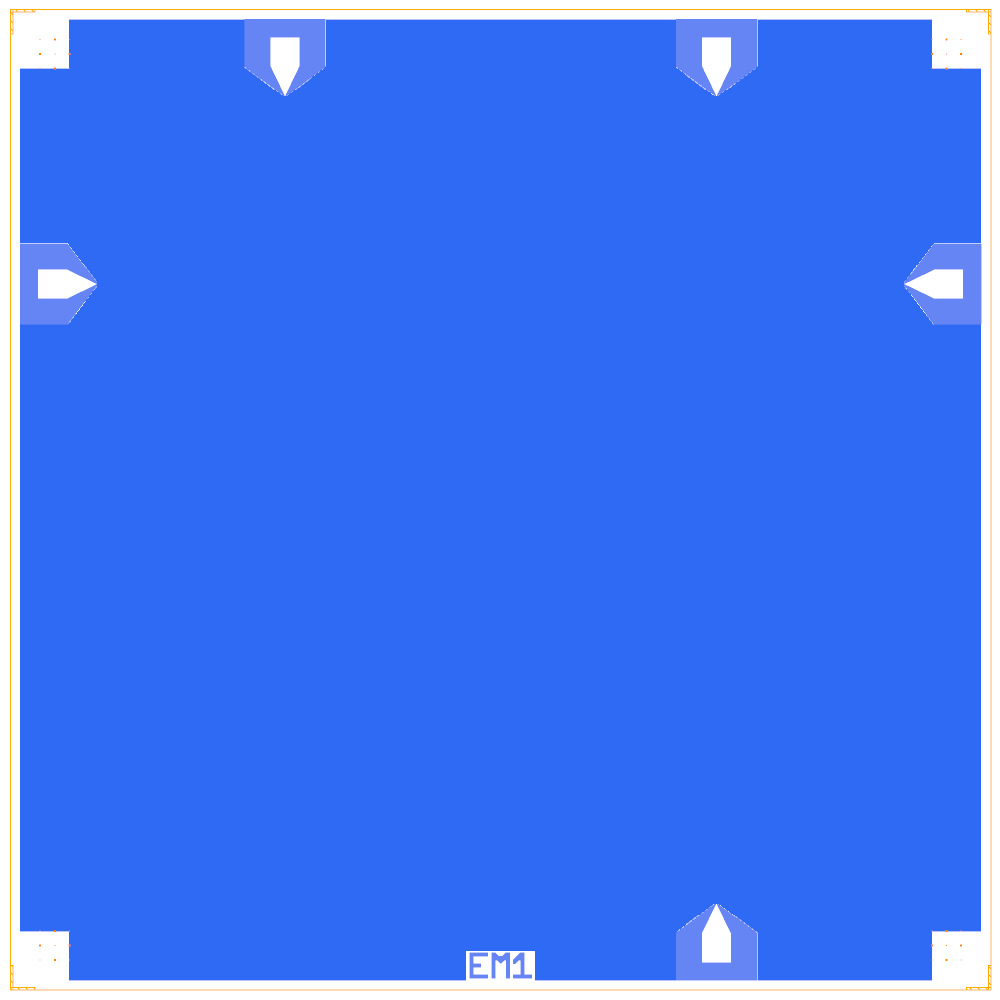

In [5]:
pads = {1: "DL-QB1", 2: "DL-QB2", 3: "PL-1-OUT", 5: "DL-QB3", 8: "PL-1-IN"}   # KQC launcher assignment (SMA8)
d = Designer("munchqubits", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "assign": pads},
             chip={"name_chip": "EM1", "with_grid": True}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

SMA8 launchers get `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** from the PDK pad rule (KQC: 800): the
outer etch edge is `frame.pad_edge` (100 µm) from the die edge. The launcher legs below start at
`corner(L[...])` (one turn radius out of the launcher port), so they follow the 80 µm shift.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.DL-QB1 | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

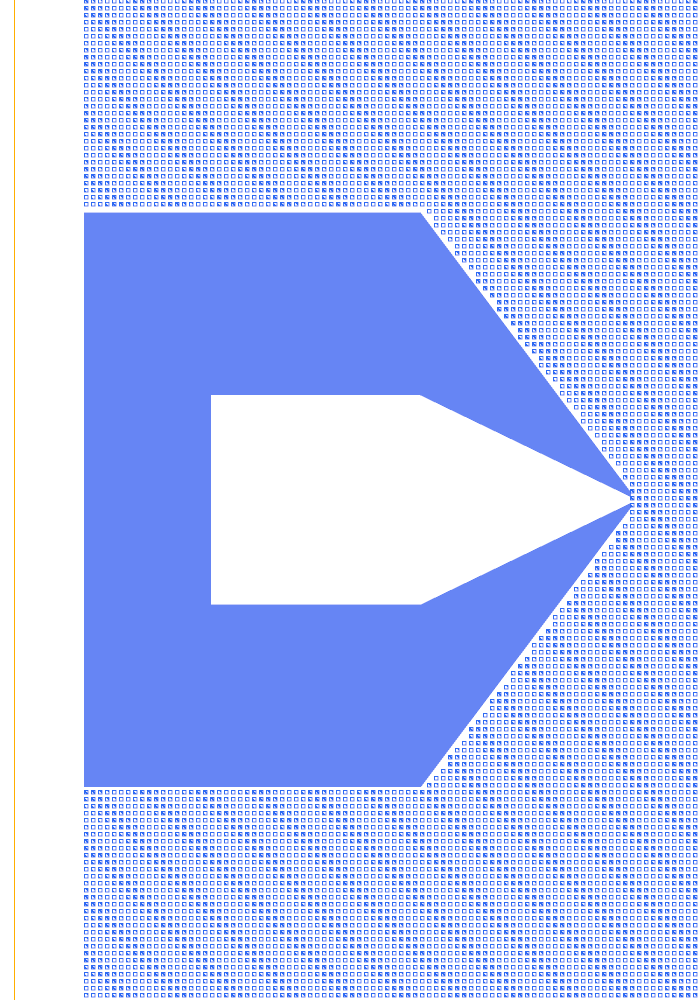

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## 5 · Components

**Circular transmons** (`CircularTransmonSingleIsland`, QB1 and QB2): a 300 µm-radius island in a 200 µm ground
gap, two arc couplers at 400 µm radius (`couplers_angle`, `couplers_a/b/width`, `couplers_arc_amplitude`), the
drive at 550 µm and the SQUID at 90°. Ports: `coupler_1`, `coupler_2`, `drive`.

**Double-pad qubit** (`DoublePads`, QB3): two floating 1000 × 200 µm islands 200 µm apart in a 1400 × 900 µm
ground gap, rotated 180° at (5000, 4000); ports `cplr`, `drive`.

**Probe-line splitters**: three `WaveguideCoplanarSplitter`s at y = 1500 (angles 180/90/0, arms 50/150/50 µm,
airbridges on), and on each the readout's `SmoothCapacitor` (finger control 3.32 / 4.21 / 1.46, 160 µm) snapped
to the splitter's `b` arm.

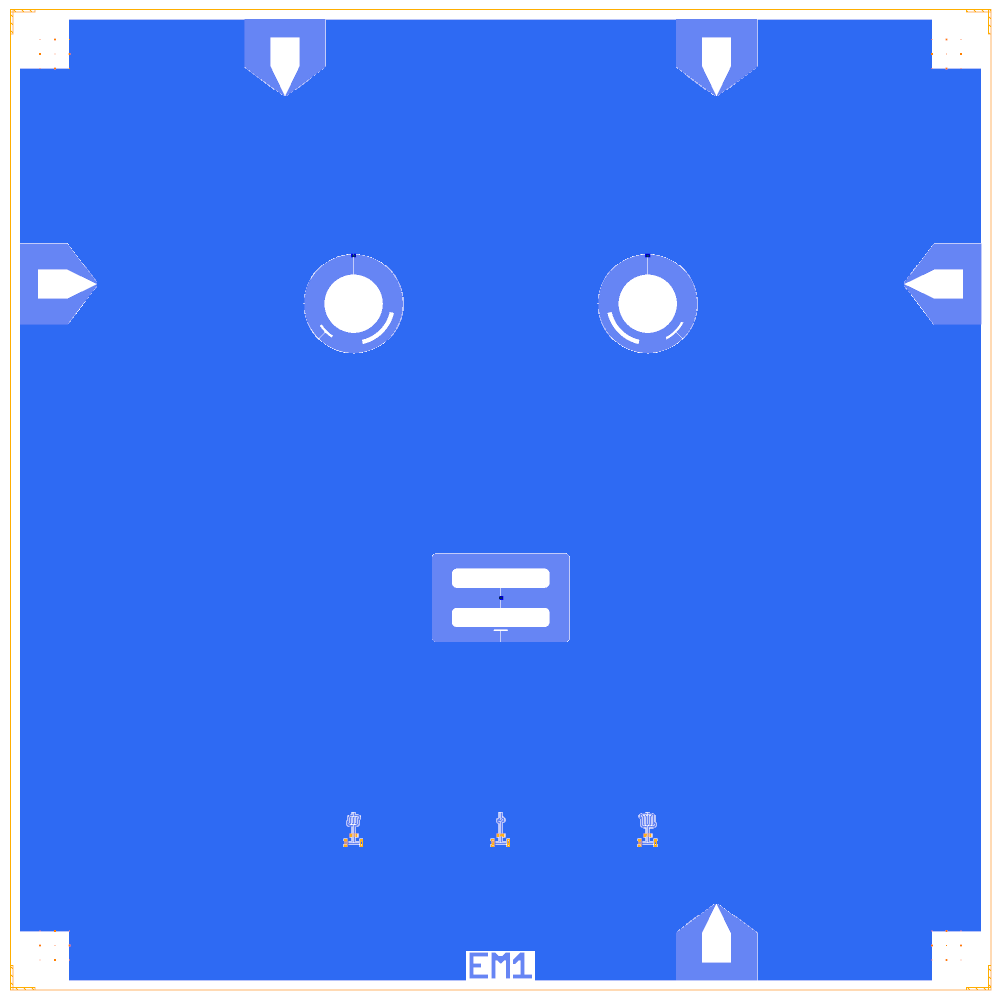

In [7]:
with d.batch():
    circ = dict(r_island=300, ground_gap=200, squid_angle=90, couplers_r=400, couplers_a=[10.0, 3.0],
                couplers_b=[6.0, 32.0], couplers_width=[30.0, 50.0], drive_distance=550.0)
    d.add("QB1", "CircularTransmonSingleIsland", at=(3500, 7000), junction=JUNCTION["QB1"], **JJ_PARAMS["QB1"],
          drive_angle=110, couplers_angle=[225.0, 315.0], couplers_arc_amplitude=[25.0, 65.0], **circ)
    d.add("QB2", "CircularTransmonSingleIsland", at=(6500, 7000), junction=JUNCTION["QB2"], **JJ_PARAMS["QB2"],
          drive_angle=70, couplers_angle=[315.0, 225.0], couplers_arc_amplitude=[35.0, 65.0], **circ)
    d.add("QB3", "DoublePads", at=(5000, 4000), rot=180, coupler_extent=[150, 20], island1_extent=[1000, 200],
          island2_extent=[1000, 200], island_island_gap=200, ground_gap=[1400, 900], drive_position=[-1100, 400],
          junction=JUNCTION["QB3"], **JJ_PARAMS["QB3"])
    tee = {q: d.add(f"T{q}", "WaveguideCoplanarSplitter", at=(x, 1500), angles=[180, 90, 0], lengths=[50, 150, 50],
                    use_airbridges=True) for q, x in (("QB1", 3500), ("QB3", 5000), ("QB2", 6500))}
    for i, (q, fingers) in enumerate((("QB1", 3.32), ("QB2", 4.21), ("QB3", 1.46)), start=1):
        d.add(f"RC{i}", "SmoothCapacitor", snap="a", to=tee[q].b, finger_control=fingers, finger_width=10,
              ground_gap=10, finger_gap=5, fixed_length=160)
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

**Resonant coupler** QB1 ↔ QB2: 9800 µm, a = 3, b = 32 µm, galvanic at both arc couplers (`term1=0, term2=0`),
with the meander on the middle segment through (4500, 6500) → (5500, 6500). **Probe line** WN → three splitters
→ EN, the diagonal launcher legs starting at the launcher corners. `corner(ref)` is KQC's `"<port>_corner"`
refpoint (one turn radius out along the port).

In [8]:
def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


with d.batch():
    d.route("CPL", "QB1.coupler_2", "QB2.coupler_2", nodes=[corner("QB1.coupler_2"), (4500, 6500), (5500, 6500),
                                                            corner("QB2.coupler_2")],
            meander=9800, a=3, b=32, term1=0, term2=0)
    d.route("PL0", L["PL-1-IN"], tee["QB1"].a, nodes=[corner(L["PL-1-IN"]), (2500, 1500)])
    d.route("PL1", tee["QB1"].c, tee["QB3"].a)
    d.route("PL2", tee["QB3"].c, tee["QB2"].a)
    d.route("PL3", tee["QB2"].c, L["PL-1-OUT"], nodes=[(7500, 1500), corner(L["PL-1-OUT"])])

**Readouts** (λ/2: both ends capacitive): from the qubit coupler's corner 300 µm down, a meander, then 100 µm and
a diagonal into the capacitor's corner, with KQC's totals 11500 / 12700 / 8000 µm. **Charge lines** with a 6 µm
open end; QB3's crosses the probe line on an airbridge between the QB3 and QB2 splitters (`d.waypoint(...,
airbridge=True)`).

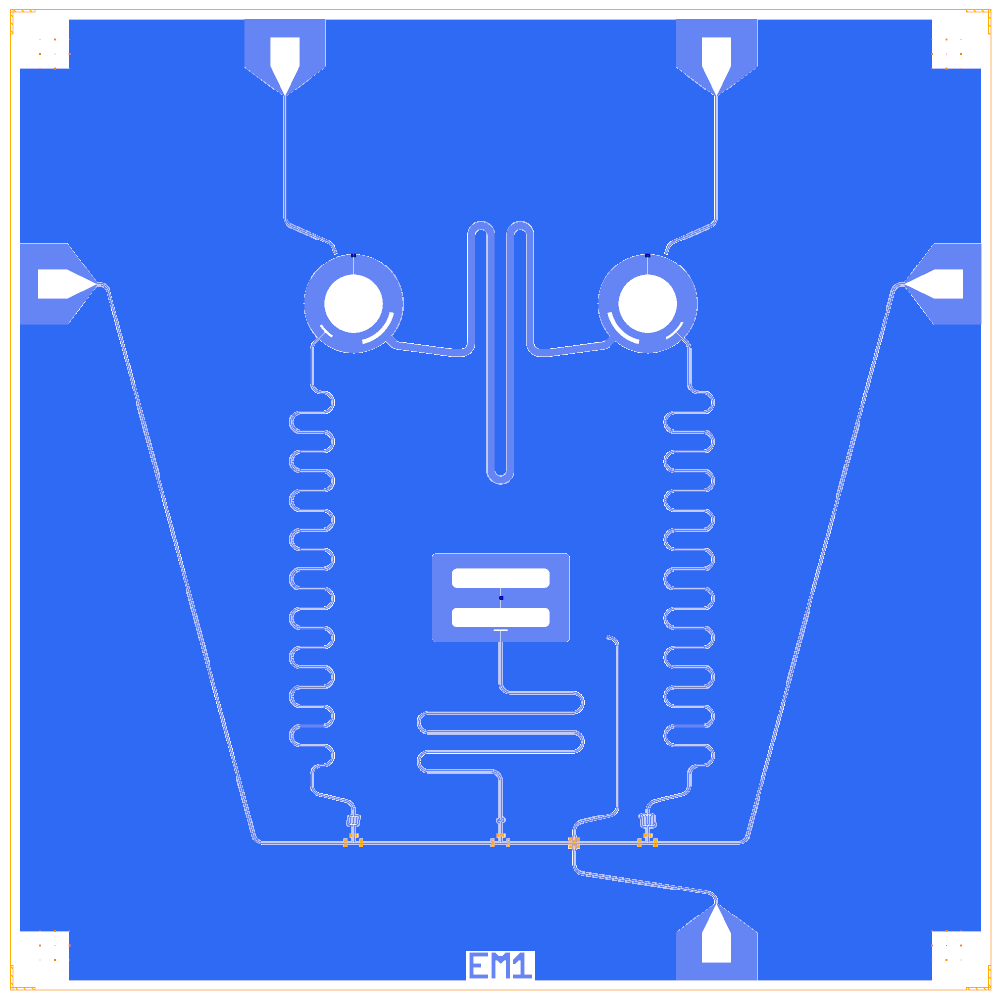

{'CPL': 9800.0, 'RR1': 11500.0, 'RR2': 12700.0, 'RR3': 8000.0}


In [9]:
with d.batch():
    for i, (q, port, length) in enumerate((("QB1", "coupler_1", 11500), ("QB2", "coupler_1", 12700),
                                           ("QB3", "cplr", 8000)), start=1):
        qc, bc = corner(f"{q}.{port}"), corner(f"RC{i}.b")
        d.route(f"RR{i}", f"{q}.{port}", f"RC{i}.b", nodes=[qc, (qc[0], qc[1] - 300), (qc[0], bc[1] + 200),
                                                            (qc[0], bc[1] + 100), bc], meander=length)
    for i in (1, 2):
        c = corner(L[f"DL-QB{i}"])
        d.route(f"DL{i}", L[f"DL-QB{i}"], f"QB{i}.drive", nodes=[c, (c[0], c[1] - 1200), corner(f"QB{i}.drive")],
                term2=6)
    xc = (5000 + 6500) / 2
    dc = corner("QB3.drive")
    d.route("DL3", L["DL-QB3"], "QB3.drive", term2=6,
            nodes=[corner(L["DL-QB3"]), (xc, 1200), d.waypoint((xc, 1500), airbridge=True), (xc, 1700),
                   (dc[0], 1800), dc])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "CPL"))})

**Sim groups, centring, save.** A Q3D C-matrix job for the coupled circular pair with its resonant coupler and
one for QB3 with its readout and capacitor. `center_in_die` confirms the content is centred (no shift); then
`munchqubits.json` is saved.

In [10]:
d.sim_group("QB1_QB2_CPL", ["QB1", "QB2", "CPL"], analyses=["q3d_cmatrix"])
d.sim_group("QB3_RR3", ["QB3", "RR3", "RC3"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "munchqubits.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer munchqubits: 9 instances, 11 routes, live=False> → examples\designs\kqc\munchqubits.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean with no warnings. `pdk_rn` applies the 40–50 kΩ window to each SQUID's parallel R_n
(43.3 / 41.7 / 45 kΩ), so none is flagged.

In [11]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 3 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

Circular transmon → island node (C and SQUID to ground) + one node per arc coupler; DoublePads → two floating
island nodes with the SQUID between them and a coupler node. The coupler route (a meander between two
component ports, galvanic at both ends) is a λ/2 bus joining both arc-coupler nodes; the readouts are λ/2
resonators on the capacitor nodes; the probe line is one node between the WN and EN 50 Ω ports.

In [12]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1 and QB3 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("QB1.", "QB3.")))))

**13 nodes · 39 branches · 3 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB1` | `QB1.island` |
| `QB1.coupler_1` | `QB1.coupler_1`, `RC1.b` |
| `QB1.coupler_2` | `QB1.coupler_2`, `QB2.coupler_2` |
| `QB2` | `QB2.island` |
| `QB2.coupler_1` | `QB2.coupler_1`, `RC2.b` |
| `QB3.island1` | `QB3.island1` |
| `QB3.island2` | `QB3.island2` |
| `QB3.cplr` | `QB3.cplr`, `RC3.b` |
| `TQB1.t` | `TQB1.t`, `TQB3.t`, `TQB2.t`, `RC1.a`, `RC2.a`, `RC3.a`, `chip.PL-1-IN`, `chip.PL-1-OUT` |
| `chip.DL-QB1` | `chip.DL-QB1` |
| `chip.DL-QB2` | `chip.DL-QB2` |
| `chip.DL-QB3` | `chip.DL-QB3` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB1` | C | `QB1` – `gnd` | 165 fF |
| `J_QB1` | SQUID | `QB1` – `gnd` | Lj 6.48 nH, Cj 15.6 fF |
| `Cg_QB1_coupler_1` | C | `QB1` – `QB1.coupler_1` | 13 fF |
| `Cc_QB1_coupler_1` | C | `QB1.coupler_1` – `gnd` | 21 fF |
| `Cg_QB1_coupler_2` | C | `QB1` – `QB1.coupler_2` | 38 fF |
| `Cc_QB1_coupler_2` | C | `QB1.coupler_2` – `gnd` | 31 fF |
| `C_QB2` | C | `QB2` – `gnd` | 165 fF |
| `J_QB2` | SQUID | `QB2` – `gnd` | Lj 6.24 nH, Cj 16.2 fF |
| `Cg_QB2_coupler_1` | C | `QB2` – `QB2.coupler_1` | 18 fF |
| `Cc_QB2_coupler_1` | C | `QB2.coupler_1` – `gnd` | 24 fF |
| `Cg_QB2_coupler_2` | C | `QB2` – `QB1.coupler_2` | 38 fF |
| `Cc_QB2_coupler_2` | C | `QB1.coupler_2` – `gnd` | 31 fF |
| `C_QB3_1` | C | `QB3.island1` – `gnd` | 132 fF |
| `C_QB3_2` | C | `QB3.island2` – `gnd` | 132 fF |
| `C_QB3_12` | C | `QB3.island1` – `QB3.island2` | 40.7 fF |
| `J_QB3` | SQUID | `QB3.island1` – `QB3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB3_cplr` | C | `QB3.island1` – `QB3.cplr` | 14.3 fF |
| `Cc_QB3_cplr` | C | `QB3.cplr` – `gnd` | 7.8 fF |
| `C_RC1` | C | `TQB1.t` – `QB1.coupler_1` | 34 fF |
| `C_RC1_a` | C | `TQB1.t` – `gnd` | 13 fF |
| `C_RC1_b` | C | `QB1.coupler_1` – `gnd` | 13 fF |
| `C_RC2` | C | `TQB1.t` – `QB2.coupler_1` | 53 fF |
| `C_RC2_a` | C | `TQB1.t` – `gnd` | 18 fF |
| `C_RC2_b` | C | `QB2.coupler_1` – `gnd` | 18 fF |
| `C_RC3` | C | `TQB1.t` – `QB3.cplr` | 8.4 fF |
| `C_RC3_a` | C | `TQB1.t` – `gnd` | 4.6 fF |
| `C_RC3_b` | C | `QB3.cplr` – `gnd` | 4.6 fF |
| `Port_PL-1-IN` | R | `TQB1.t` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `TQB1.t` – `gnd` | 50 Ω |
| `Port_DL-QB1` | R | `chip.DL-QB1` – `gnd` | 50 Ω |
| `Port_DL-QB2` | R | `chip.DL-QB2` – `gnd` | 50 Ω |
| `Port_DL-QB3` | R | `chip.DL-QB3` – `gnd` | 50 Ω |
| `Cd_QB1` | C | `QB1` – `chip.DL-QB1` | 0.1 fF |
| `Cd_QB2` | C | `QB2` – `chip.DL-QB2` | 0.1 fF |
| `Cd_QB3` | C | `QB3.island1` – `chip.DL-QB3` | 0.1 fF |
| `CPL` | TLres | `QB1.coupler_2` – `gnd` | lambda/2, 9800 µm, 6.362 GHz |
| `RR1` | TLres | `QB1.coupler_1` – `gnd` | lambda/2, 11500 µm, 5.480 GHz |
| `RR2` | TLres | `QB2.coupler_1` – `gnd` | lambda/2, 12700 µm, 4.962 GHz |
| `RR3` | TLres | `QB3.cplr` – `gnd` | lambda/2, 8000 µm, 7.877 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `DL1` | drive | `J_QB1` | `DL1` | 1902 |
| `DL2` | drive | `J_QB2` | `DL2` | 1902 |
| `DL3` | drive | `J_QB3` | `DL3` | 4260 |

**Unconnected ports:** none

**Builder notes:**

- QB3: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)

**QB1 and QB3 ports → circuit nodes:**

| port | node |
|---|---|
| `QB1.coupler_1` | `QB1.coupler_1` |
| `QB1.coupler_2` | `QB1.coupler_2` |
| `QB1.drive` | `control:drive` |
| `QB3.cplr` | `QB3.cplr` |
| `QB3.drive` | `control:drive` |

## 9 · LOM simulation

Four groups: the two circular qubits with the resonant coupler (two qubit modes + the λ/2 bus, and the static ZZ
of QB1–QB2: circuit neighbours through the bus), and each qubit with its readout, capacitor and the whole probe
line (splitters + routes, so κ goes into the two 50 Ω launchers). Expected: f_q ≈ 4.0–4.2 GHz for the circular
qubits (sized for 4.05 GHz; the readout loading moves them a little) and ≈ 5.3 GHz for the double-pad qubit
(nominal SQUID), the bus at ≈ 5.5 GHz. Both circular qubits were sized for the same frequency, so through the bus
they are nearly degenerate and their modes hybridise (participations ≈ 0.75 / 0.2 in the mode table): the ZZ
table says so, and a per-pair ZZ needs detuned junctions (or the C-matrix of the pair).

In [13]:
groups = {"QB1+QB2+CPL": ["QB1", "QB2", "CPL"]}
for i, q in enumerate(("QB1", "QB2", "QB3"), start=1):
    groups[f"{q}+RR{i}"] = [q, f"RR{i}", f"RC{i}", "TQB1", "TQB3", "TQB2", "PL0", "PL1", "PL2", "PL3"]
results = simulate_groups(d, groups, max_modes=3)
display(Markdown(groups_md(results)))
display(Markdown("**Static ZZ between the two circular qubits (QuTiP, through the resonant coupler):**\n\n"
                 + zz_md({"QB1+QB2+CPL": results["QB1+QB2+CPL"]})))
for g, r in results.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| QB1+QB2+CPL | QB1 | 4.0164 | -64.49 | CPL | 5.5259 | 0 | -8.14 |
|  | QB2 | 4.1024 | -44.48 | – | – | – | – |
| QB1+RR1 | QB1 | 4.2116 | -95.89 | RR1 | 5.2365 | 5.46 | -1.01 |
| QB2+RR2 | QB2 | 4.2287 | -88.44 | RR2 | 4.6998 | 9.08 | -5.71 |
| QB3+RR3 | QB3 | 5.3224 | -165.8 | RR3 | 7.6566 | 1.06 | -0.488 |

**Static ZZ between the two circular qubits (QuTiP, through the resonant coupler):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| QB1+QB2+CPL | QB1-QB2 | – | yes | yes |

**QB1+QB2+CPL, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB1 | qubit | 4.0967 | 0 | 47.1 | J_QB1 0.73, J_QB2 0.20, CPL 0.07 |
| QB2 | qubit | 4.1885 | 0 | 52.9 | J_QB2 0.76, J_QB1 0.23 |
| CPL | resonator | 5.5348 | 0 | 0.5 | CPL 0.92, J_QB2 0.04, J_QB1 0.04 |

**QB1+RR1, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB1 | qubit | 4.3051 | 0.0143 | 90.7 | J_QB1 0.99 |
| RR1 | resonator | 5.2371 | 5.46 | 0.0 | RR1 0.99 |

**QB2+RR2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB2 | qubit | 4.3161 | 0.352 | 79.9 | J_QB2 0.95, RR2 0.05 |
| RR2 | resonator | 4.7040 | 9.08 | 0.3 | RR2 0.95, J_QB2 0.05 |

**QB3+RR3, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB3 | qubit | 5.4817 | 0.000365 | 154.3 | J_QB3 1.00 |
| RR3 | resonator | 7.6568 | 1.06 | 0.0 | RR3 1.00 |

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: the coupled circular pair with its resonant coupler, and QB3 with its readout and capacitor (Q3D).

In [14]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB1_QB2_CPL · q3d_cmatrix | `build/jobs/munchqubits_QB1_QB2_CPL_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · junction · `QB2.junction`<br>3 · waveguide · `QB1.coupler_2`<br>4 · waveguide · `QB2.coupler_2`<br>5 · edge · `DL1`<br>6 · edge · `DL2`<br>7 · edge · `RR1`<br>8 · edge · `RR2` | `QB1.island`, `QB2.island`, `QB1.coupler_2`, `QB2.coupler_2`, `DL1`, `DL2`, `RR1`, `RR2` |
| QB3_RR3 · q3d_cmatrix | `build/jobs/munchqubits_QB3_RR3_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · waveguide · `QB3.cplr`<br>3 · waveguide · `RC3.b`<br>4 · edge · `DL3`<br>5 · edge · `PL1`<br>6 · edge · `PL2` | `QB3.island1`, `QB3.cplr`, `RC3.b`, `DL3`, `PL1`, `QB3.island2` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [15]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB1_QB2_CPL · q3d_cmatrix, QB3_RR3 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The resonant coupler is a λ/2 bus: its length sets its frequency, and the qubit–qubit interaction it mediates
depends on how far the bus sits from the qubits. Shorten it from 9800 to 9000 µm: the bus mode moves up by
≈ 0.4 GHz (5.53 → 5.93 GHz), further from the qubits, so the bus's dispersive shift χ shrinks (≈ −8 → −6 MHz)
and QB1 moves up by ≈ 14 MHz; the two qubits stay hybridised. The change is made on a copy (`design_copy`), so
`munchqubits.json` keeps KQC's 9800 µm.

In [16]:
def modes_delta_md(r0, r1):                      # before/after of every normal mode (QuCat)
    m0, m1 = {m.label: m for m in r0.modes}, {m.label: m for m in r1.modes}
    rows = ["| mode | kind | f before (GHz) | f after (GHz) | Δf (MHz) | A before (MHz) | A after (MHz) |",
            "|---|---|---|---|---|---|---|"]
    for k in m0:
        if k in m1:
            a, b = m0[k], m1[k]
            rows.append(f"| {k} | {a.kind} | {a.f_GHz:.4f} | {b.f_GHz:.4f} | {1e3 * (b.f_GHz - a.f_GHz):+.1f} | "
                        f"{a.anharmonicity_MHz:.1f} | {b.anharmonicity_MHz:.1f} |")
    return "\n".join(rows)

d2 = design_copy(DESIGN)
d2["CPL"].set(meander=9000)
after = simulate_groups(d2, {"QB1+QB2+CPL": groups["QB1+QB2+CPL"]}, max_modes=3)
display(Markdown("**CPL: 9800 → 9000 µm**\n\n" + modes_delta_md(results["QB1+QB2+CPL"], after["QB1+QB2+CPL"])))
display(Markdown(params_delta_md({"QB1+QB2+CPL": results["QB1+QB2+CPL"]}, after)))
display(Markdown("**Static ZZ after:**\n\n" + zz_md(after)))

**CPL: 9800 → 9000 µm**

| mode | kind | f before (GHz) | f after (GHz) | Δf (MHz) | A before (MHz) | A after (MHz) |
|---|---|---|---|---|---|---|
| QB1 | qubit | 4.0967 | 4.1111 | +14.4 | 47.1 | 54.3 |
| QB2 | qubit | 4.1885 | 4.1903 | +1.8 | 52.9 | 57.8 |
| CPL | resonator | 5.5348 | 5.9320 | +397.2 | 0.5 | 0.3 |

| parameter | before | after | Δ |
|---|---|---|---|
| `QB1+QB2+CPL: QB1.f_q_GHz` | 4.0164 | 4.0285 | +0.01209 |
| `QB1+QB2+CPL: QB1.alpha_MHz` | -64.487 | -71.339 | -6.852 |
| `QB1+QB2+CPL: CPL.chi_MHz` | -8.1404 | -6.1554 | +1.985 |
| `QB1+QB2+CPL: QB2.f_q_GHz` | 4.1024 | 4.1043 | +0.001854 |
| `QB1+QB2+CPL: QB2.alpha_MHz` | -44.478 | -45.605 | -1.127 |
| `QB1+QB2+CPL: CPL.f_GHz` | 5.5259 | 5.9254 | +0.3995 |
| `QB1+QB2+CPL: CPL.kappa_MHz` | 0 | 0 | +0 |

**Static ZZ after:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| QB1+QB2+CPL | QB1-QB2 | – | yes | yes |

## 13 · Build and export

**The design file.** `munchqubits.json` is the whole design: `qcc build examples/designs/kqc/munchqubits.json`
rebuilds `build/munchqubits.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: base etch 1/0 with the cheese (source `build`: KQC's
grid), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0, airbridges 300/301 (the
splitters' and QB3's charge-line bridge), and the frame (100/0, 1000/0, 1001/0). Corner rounding is skipped
unless `FULL_FAB`; `qcc mask examples/designs/kqc/munchqubits.json` writes the complete file.

**Simulation export options.** No cheese in simulation exports; airbridges dropped unless `airbridges=True`;
`setup.geometry` reports what was left out.

In [17]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB3_RR3", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 862714 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 839750 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 24 |
| 301/0 | AIRBRIDGE_BRIDGE | 12 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 862706 holes on the mask.

→ `build/munchqubits_fab.oas`

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 6, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

Full chip; QB1 with its two arc couplers; its SQUID; the QB3 readout capacitor on its probe-line splitter; the
die frame's south-west corner; QB1's SQUID region in the **fab view** (the mask from step 13: 1/0 with KQC's grid
holes, 3/0, the trilayer layers); and KQC's own `MunchQubits` built stand-alone for comparison. (The layout
snapshots show KQC's ground grid, as one tone at full-chip scale, and draw the chip boundary 100/0 as an
outline; the fab view shows the grid holes on 1/0 and on 3/0.)

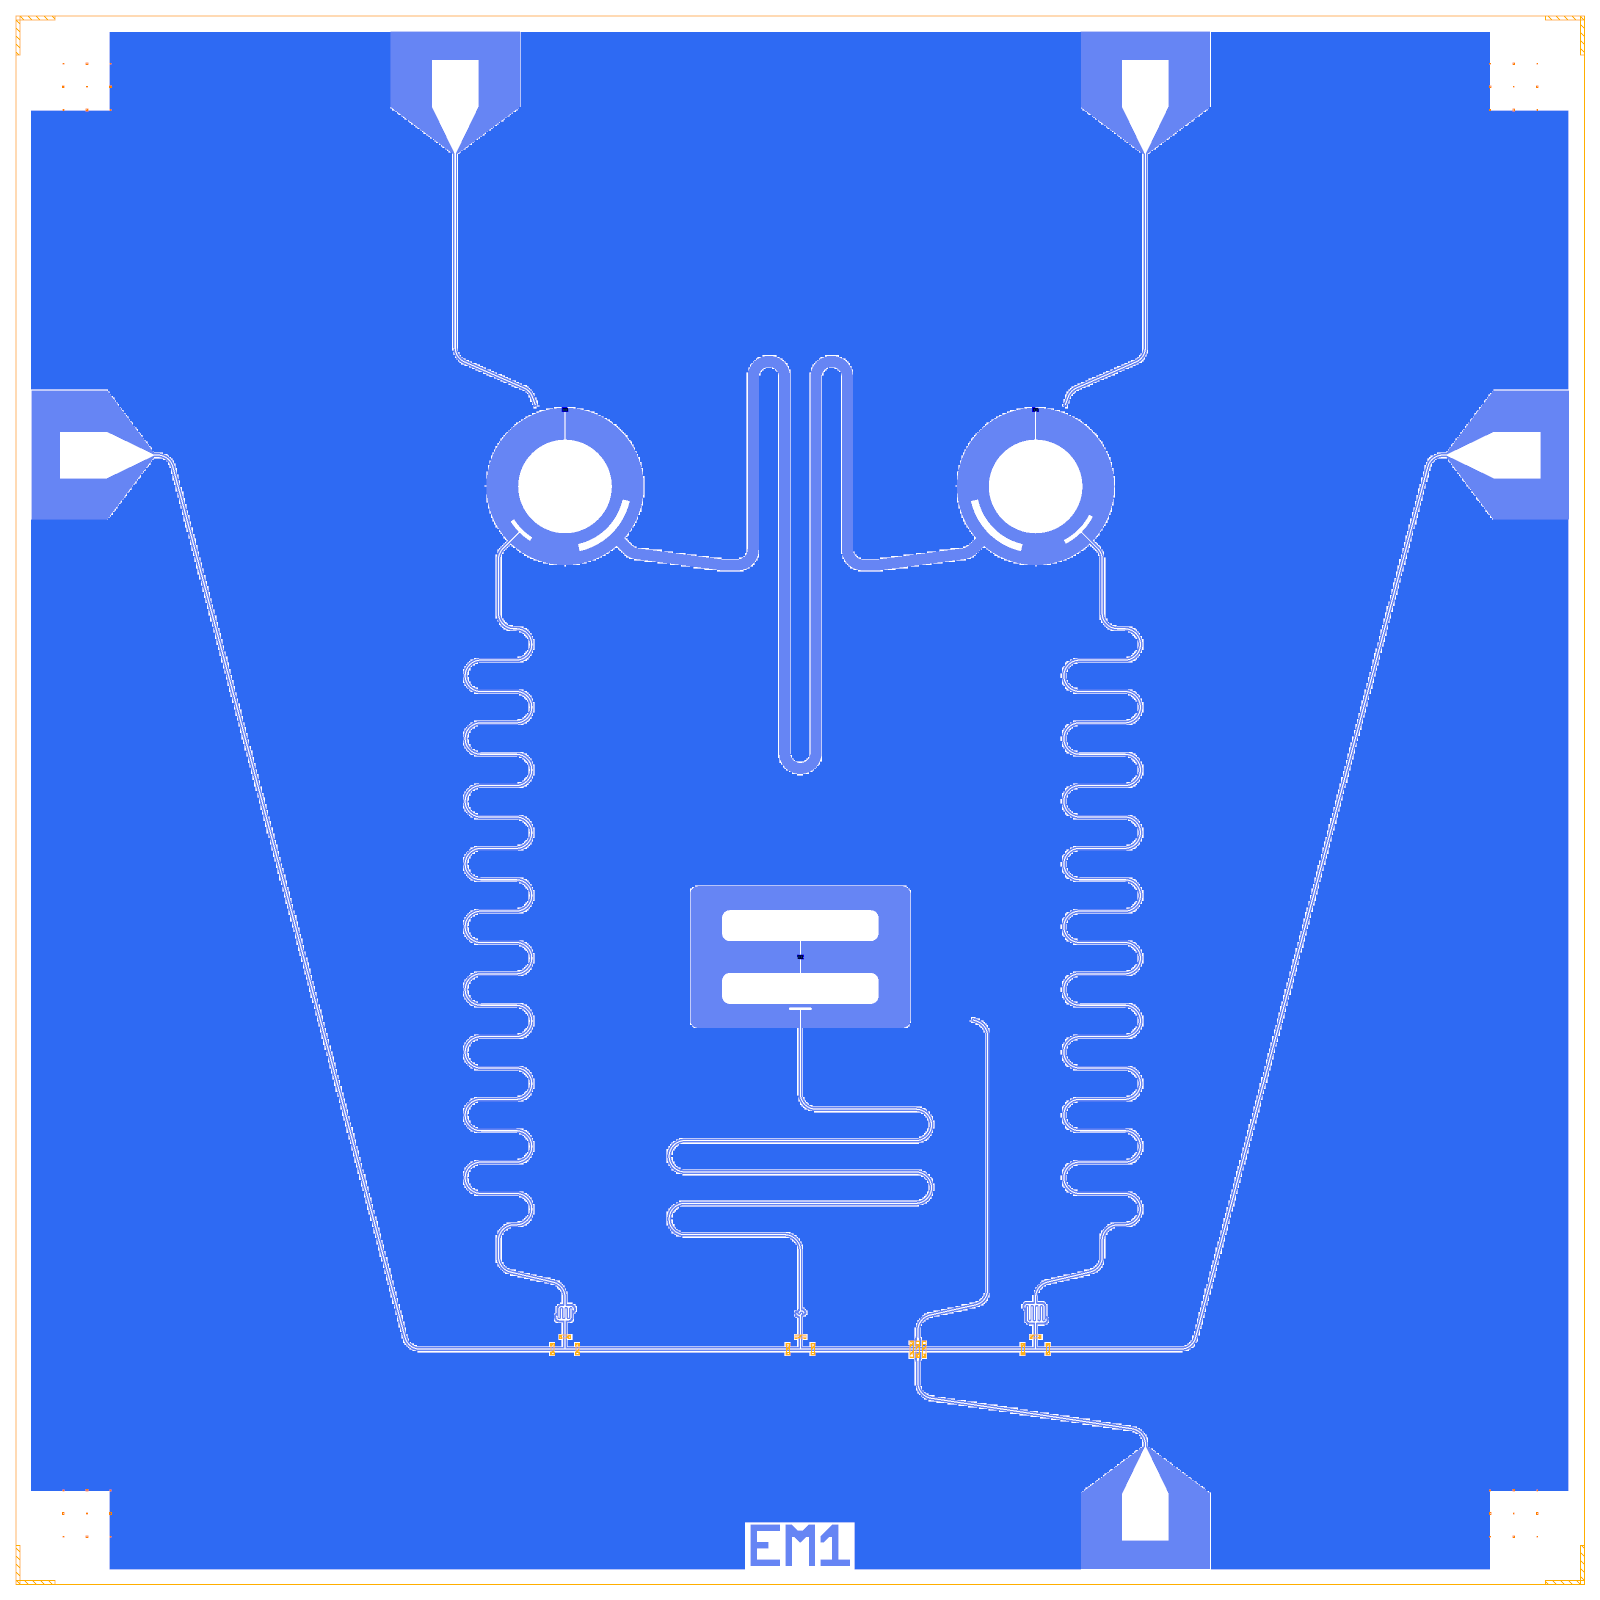

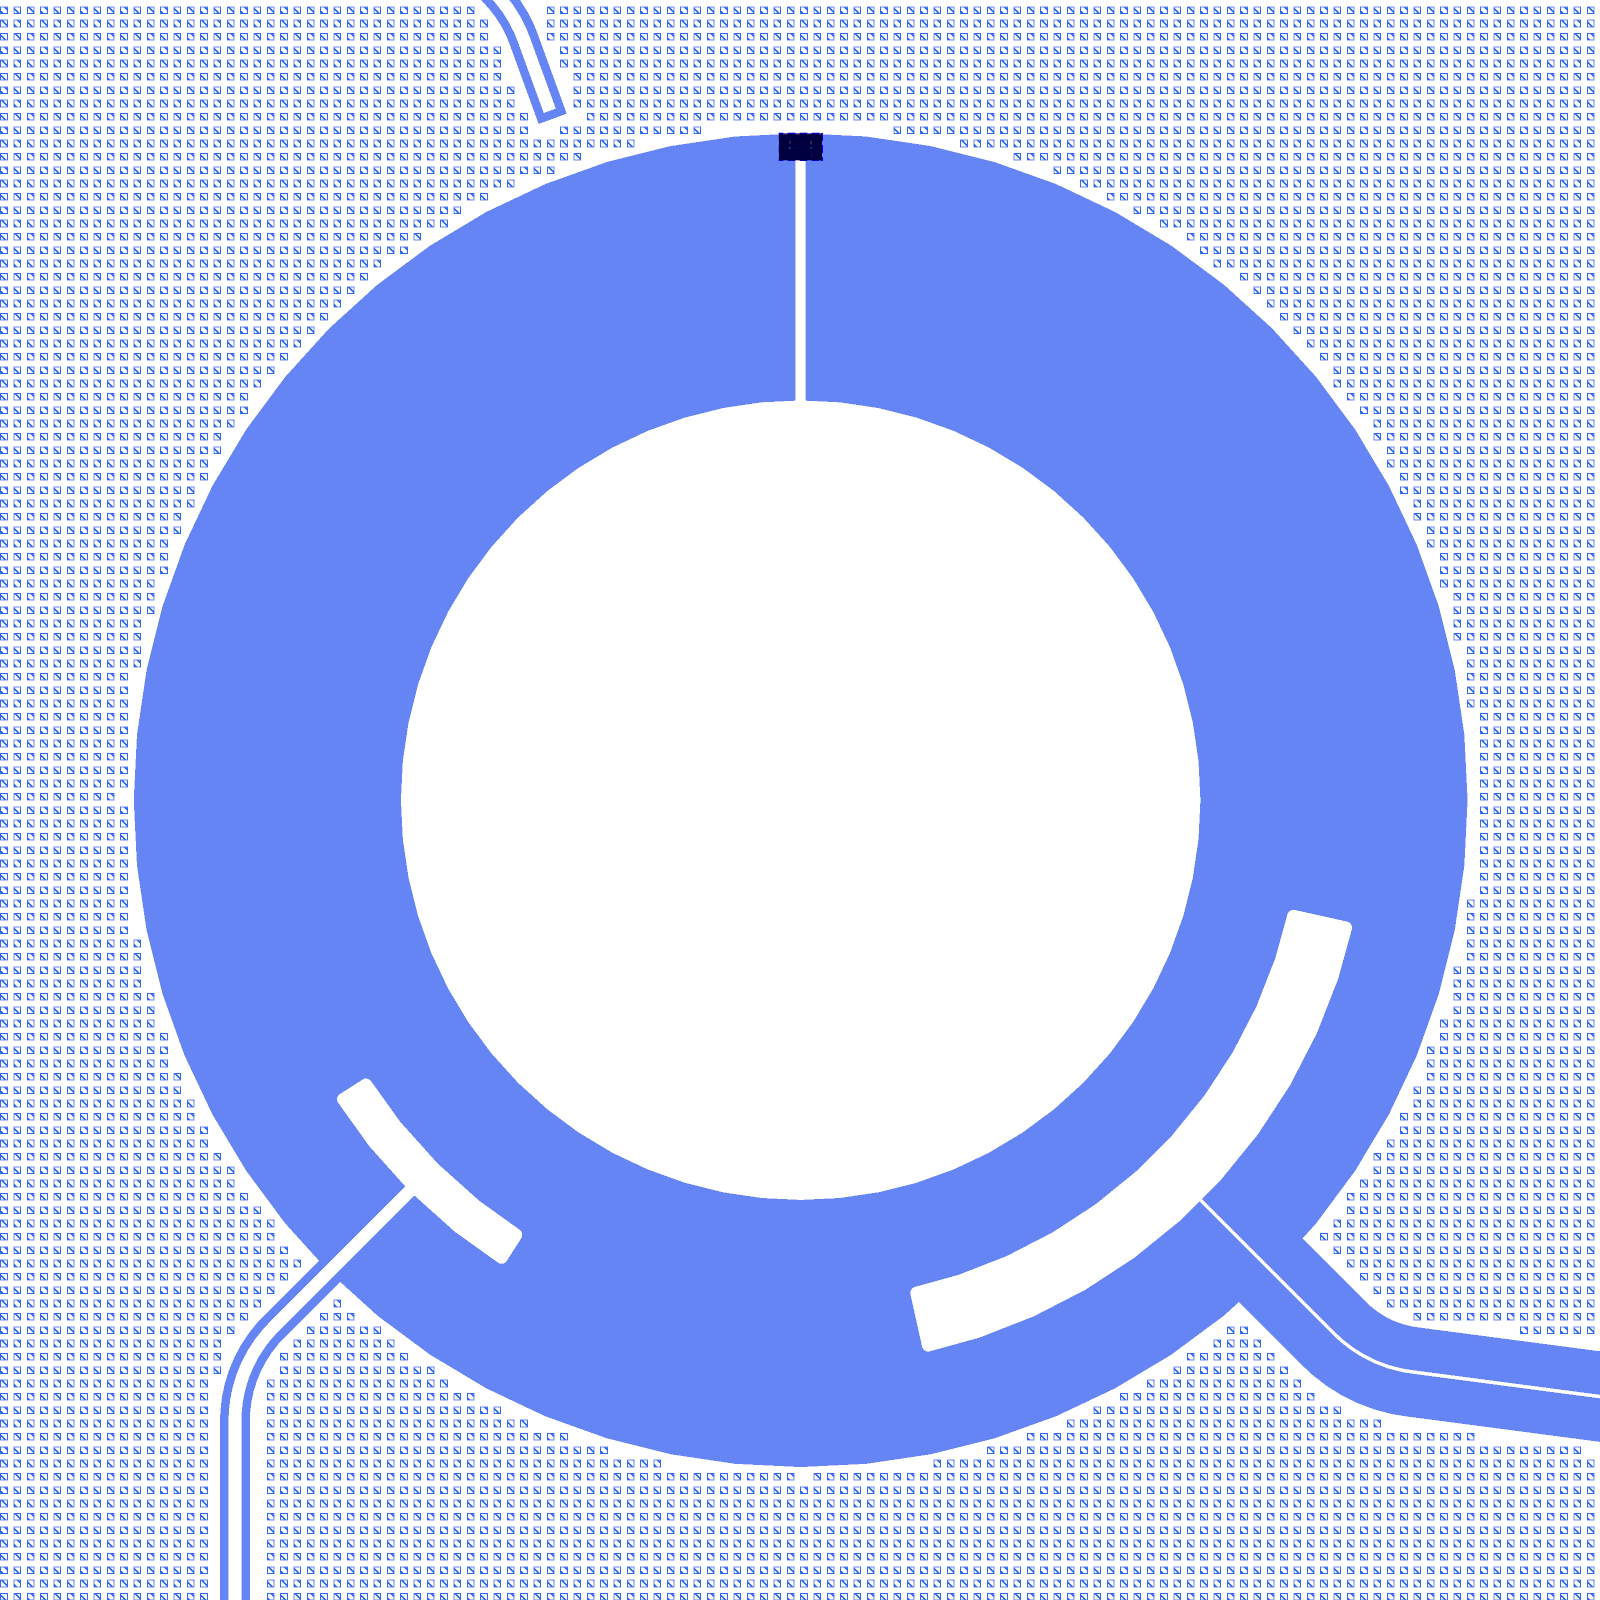

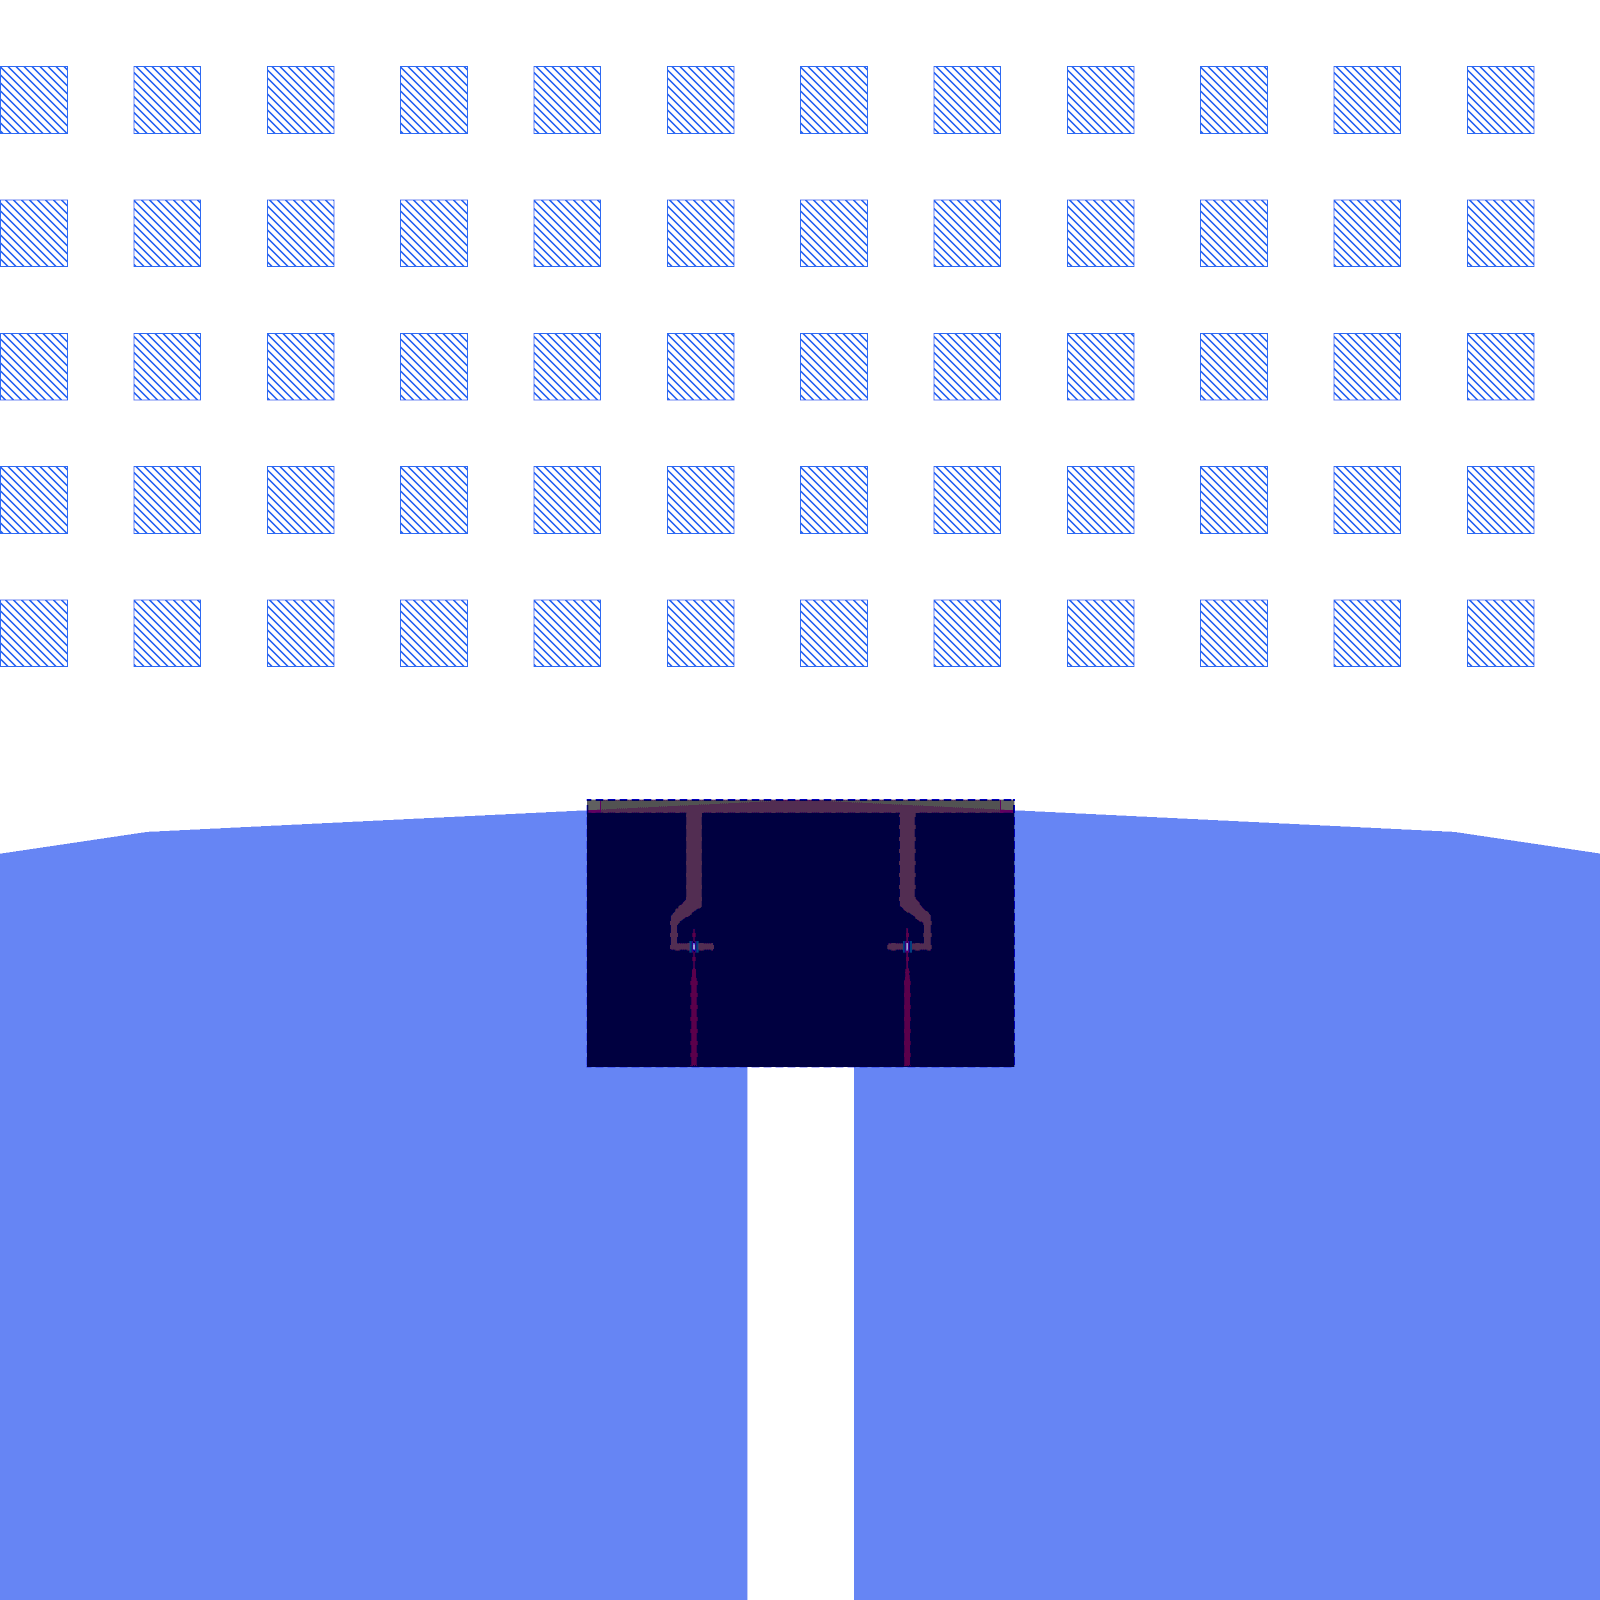

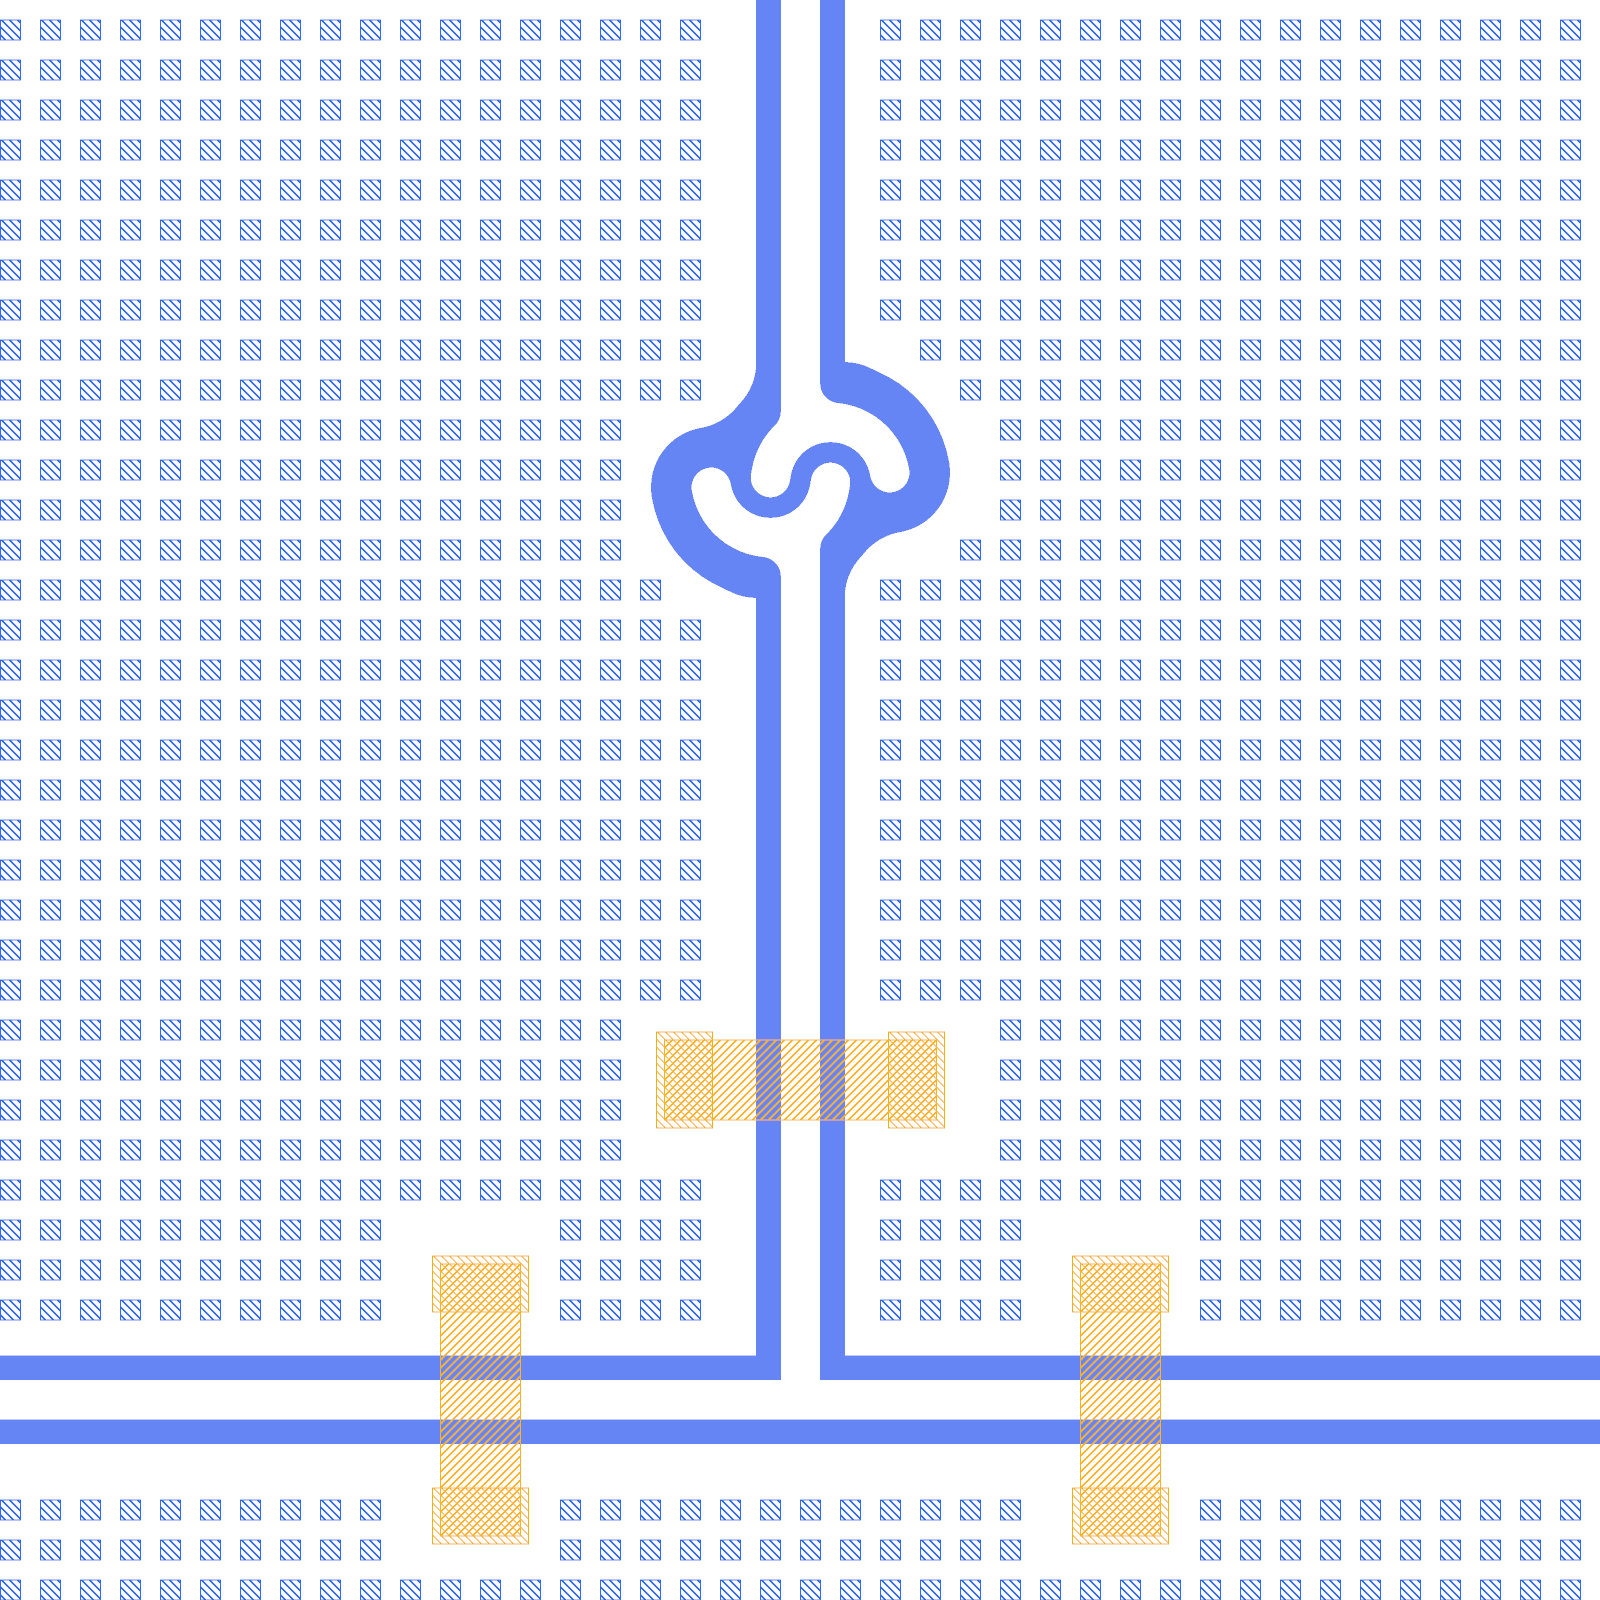

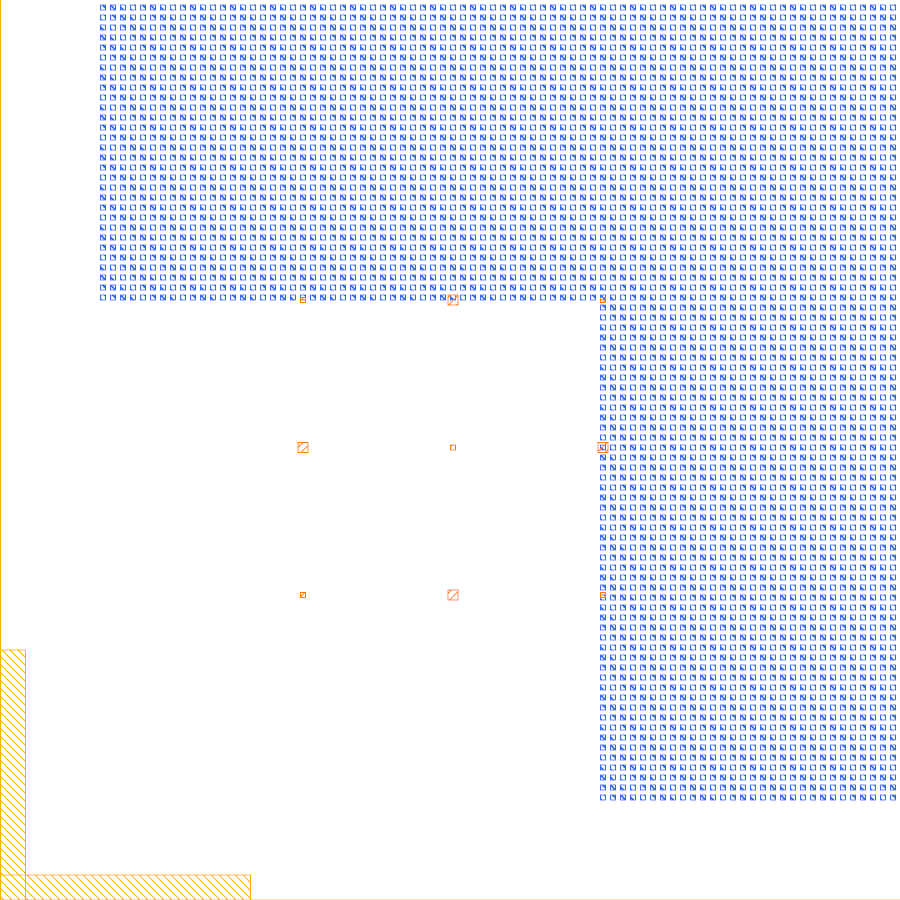

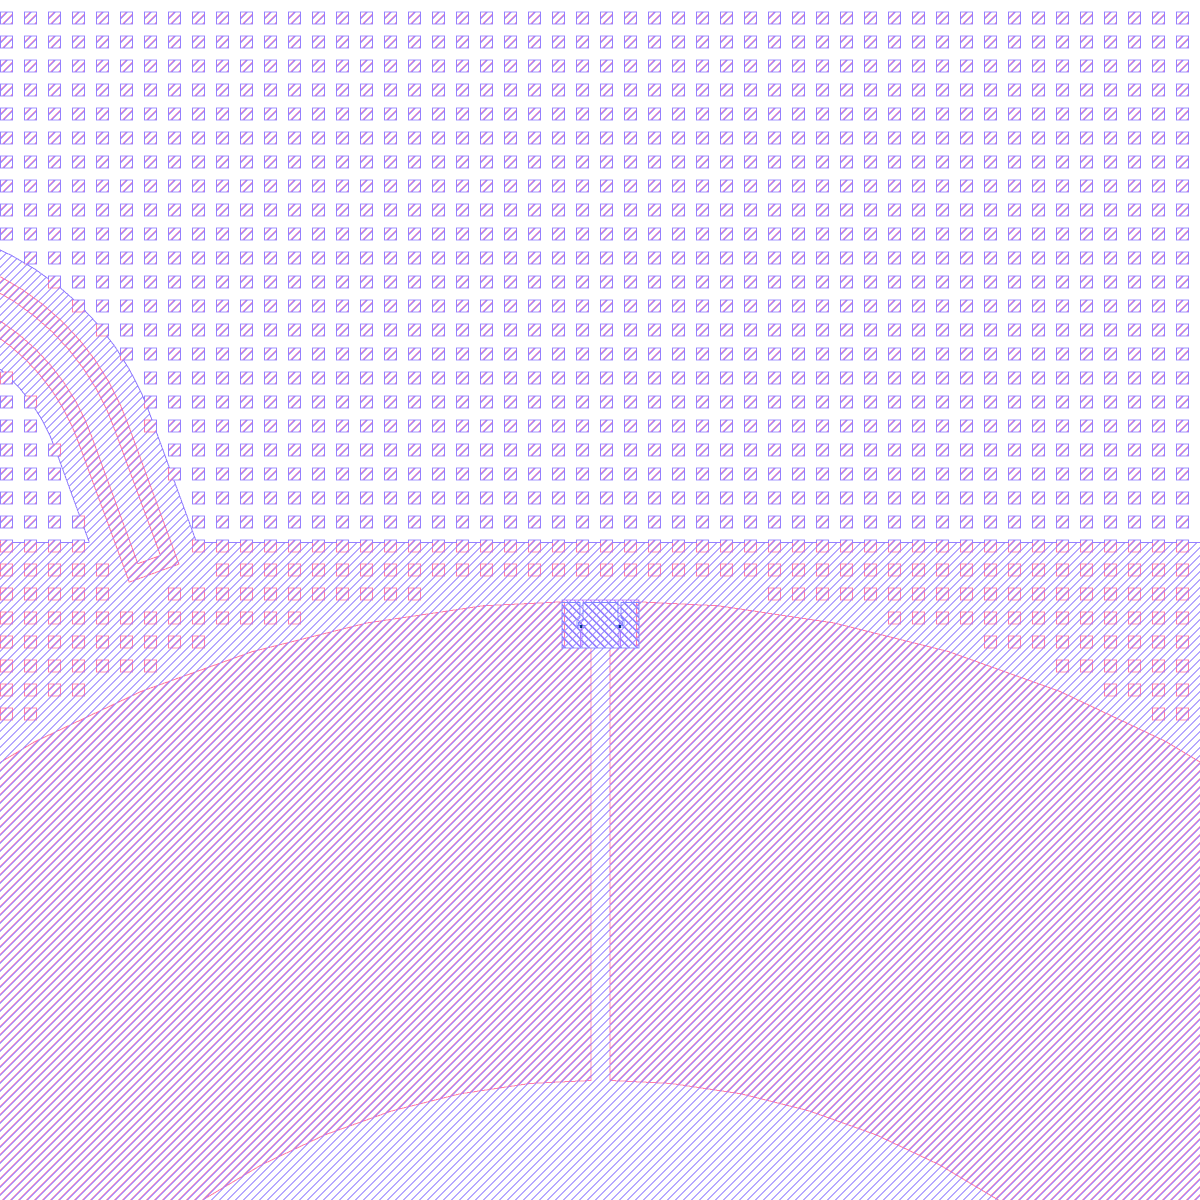

In [18]:
show_snapshot(d, OUT / "munchqubits.png", box=(-100, -100, 10100, 10100))   # chip only (KQC draws launcher names outside it)
show_snapshot(d, OUT / "munchqubits_qb1.png", box=(2900, 6400, 4100, 7600), width=480)
show_snapshot(d, OUT / "munchqubits_squid.png", box=(3440, 7440, 3560, 7560), width=360)
show_snapshot(d, OUT / "munchqubits_coupler.png", box=(4800, 1450, 5200, 1850), width=360)
show_snapshot(d, OUT / "munchqubits_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "munchqubits_fab.oas", OUT / "munchqubits_fab_qb1.png", box=(3250, 7250, 3750, 7750),
          size=(1200, 1200), width=420);

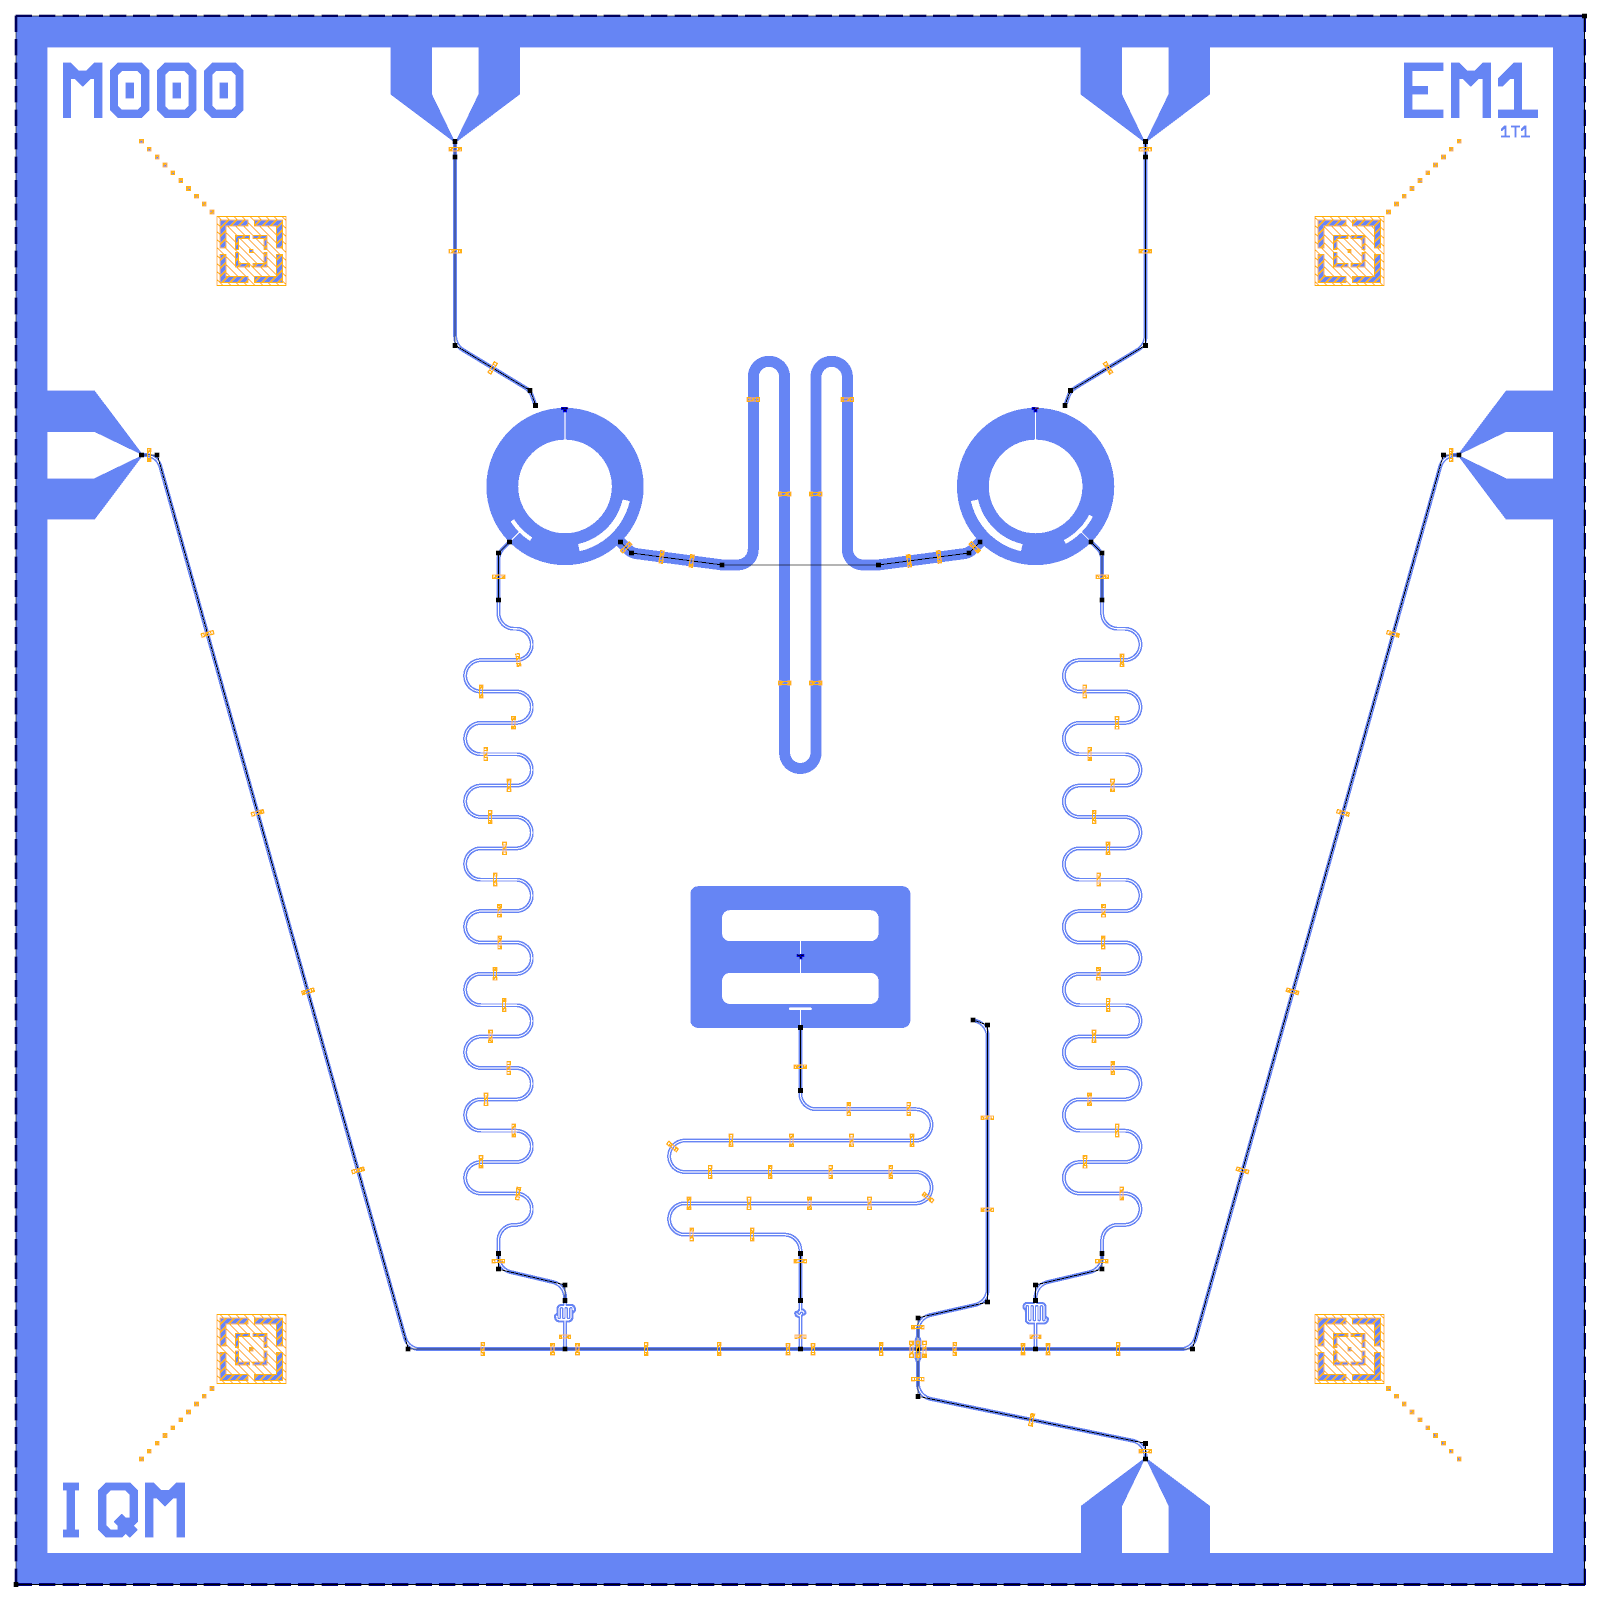

In [19]:
from kqcircuits.chips.munch_qubits import MunchQubits
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_munchqubits")
top.insert(pya.DCellInstArray(MunchQubits.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "munchqubits_kqc_original.oas"))
snap_file(Path("build") / "munchqubits_kqc_original.oas", OUT / "munchqubits_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the SMA8 assignment; the coupler, probe-line, readout and charge-line paths and lengths (9800, 11500, 12700, 8000 µm); the sim groups; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`); sapphire; trilayer SQUIDs (circular qubits sized for 4.05 GHz, the double-pad qubit at the nominal SQUID ≈ 5.3 GHz) |
| **simplified** | four probe-line routes between the splitters; router-fitted meanders; no `n_bridges` |
| **PDK design warnings** | none |
| **FEM** | 2 Q3D jobs exported (`build/jobs/munchqubits_*`), not solved here |